# Reaction kinetics and parameter fitting with Python

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 09 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/09_Reaction_Kinetics_and_Parameter_Fitting.ipynb)

**Audience:** first-year students from all engineering majors; no chemistry or kinetics course is assumed.  
**Requirements:** Python, NumPy, and Matplotlib. Run the cells in order.

## The question behind this notebook

Engineers often measure a quantity repeatedly to find out **how fast it changes**. For example, they may monitor a dissolved contaminant as it breaks down, a disinfectant as it is consumed, or a useful ingredient as it loses activity during storage. The physical details differ, but the programming task has the same shape: record a time and a measured value, propose a rule for how the value changes, and test whether that rule agrees with the measurements.

Our example follows an imaginary dissolved substance called **A**. We do not need to know its chemical formula. We measure its *concentration*: how much A is present in each liter of solution. The unit **mol/L** means moles of A per liter; a mole is a standard counting unit for particles. If the number of moles per liter decreases, less A remains in the solution. Time is measured in minutes.

At first we use a simple rule: during equal short intervals, roughly the same **fraction of what remains** disappears. This is called a *first-order* model. A number called the **rate constant** controls how rapidly the predicted concentration falls. Later we will compare that rule with two other possible patterns of change. The model is an assumption to examine, rather than a claim about every chemical process.

|---|---|
| Initial concentration $C_0$ | How much A is present per liter at the start. |
| Concentration $C_A(t)$ | How much A remains per liter after $t$ minutes. |
| Rate constant $k$ | A parameter that controls how quickly the first-order prediction falls. |
| Measurement | An observed concentration at a recorded time; it may contain error. |
| Parameter fitting | Trying values of $k$ and selecting the one whose predictions agree best with the measurements. |
| Residual | The observed value minus the value predicted by a fitted model. |

**Route through the notebook:** understand the quantities and their units → predict a concentration curve → generate a small teaching dataset → fit $k$ → inspect residuals. Clearly marked optional sections explore numerical time stepping, uncertainty, alternative rate laws, and fitting both $C_0$ and $k$. Every displayed measurement is **synthetic**: we generate it from a known rule plus random measurement error. No real chemical species or experimental data are claimed.

**Programming goals:** variables and units, functions, arrays, loops, indexing, conditional checks, random numbers, numerical search, plots, and assertions. Every executable line has a nearby explanatory comment. Figures use consistent typography and units; their stored outputs include scalable SVG and high-resolution PNG. To export any figure as PDF after running its cell, insert `fig.savefig("figure_name.pdf", bbox_inches="tight")` immediately before `plt.show()`.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 3, Getting it right |
| **Time** | about 40 min (about 80 min with exercises) |
| **Before this** | Notebooks 05 and 08; reading an x–y plot. |
| **Essential** | Sections 1–4, 8 and 9. |
| **Optional on a first reading** | Sections 5–7 (uncertainty, another rate law, an uncertain starting concentration) and the optional checks inside Sections 2 and 4. |
| **Next** | 10, Classes for engineering components. |

**You have understood this notebook if you can, without looking back:**

1. Write the first-order model C(t) = C₀e^(−kt) as a function and plot it over the measured data.
2. Define the sum of squared errors SSE(k) in code, and find the k that makes it smallest.
3. Read a residual plot and say whether the model describes the data.
4. Use bisection to find when 75% is converted, and check it against ln(4)/k.
5. Explain in one sentence why a fitted parameter is a model estimate, not a measured fact.

**Not expected of you:** The statistics behind the uncertainty intervals in Sections 5–7.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. What is a reaction rate?

A **reaction rate** describes change per unit time. Suppose a sample goes from $1.20$ to $0.90\ \mathrm{mol/L}$ in one minute. Its *average disappearance rate over that minute* is $(1.20-0.90)/1=0.30\ \mathrm{mol/(L\,min)}$. This arithmetic tells us the average loss between two measurements. The rate at one particular instant can differ as the concentration changes.

We write the concentration of A as $C_A$. A *first-order* model assumes that the disappearance rate at a particular instant is proportional to the concentration **currently remaining**:

$$\text{disappearance rate}=kC_A,\qquad [k]=\mathrm{min^{-1}}.$$

If twice as much A remains, this model predicts twice the instantaneous disappearance rate. If less A remains later, the disappearance rate slows. The proportionality factor $k$ is the **rate constant**. Its unit follows from the equation: $\mathrm{min^{-1}}$ multiplied by $\mathrm{mol/L}$ gives $\mathrm{mol/(L\,min)}$. For example, $C_A=1.20\ \mathrm{mol/L}$ and $k=0.28\ \mathrm{min^{-1}}$ imply an initial disappearance rate of $0.336\ \mathrm{mol/(L\,min)}$; the rate does not stay at that initial value as A is consumed.

Our simple model assumes that the solution is well mixed, its volume and temperature remain constant, and no additional process adds or removes A. We will use the model as an engineering approximation and check it against observations. A fitted reaction order alone does not identify the molecular steps of a reaction.

In [1]:
# Import NumPy for numerical arrays, exponential functions, and random sampling.
import numpy as np
# Import Matplotlib to create explanatory and diagnostic figures.
import matplotlib.pyplot as plt
# Use one readable font family for all figures in the notebook.
plt.rcParams["font.family"] = "DejaVu Sans"
# Keep normal figure text legible when a figure is placed on a report page.
plt.rcParams["font.size"] = 10
# Set clear but compact sizes for axis labels and titles.
plt.rcParams["axes.labelsize"] = 10
# Keep titles subordinate to the plotted data.
plt.rcParams["axes.titlesize"] = 11
# Give tick labels a slightly smaller size than axis labels.
plt.rcParams["xtick.labelsize"] = 9
# Use the same size for tick labels on vertical axes.
plt.rcParams["ytick.labelsize"] = 9
# Keep legends readable without occupying too much plot area.
plt.rcParams["legend.fontsize"] = 9
# Remove the top axis border because it conveys no extra information.
plt.rcParams["axes.spines.top"] = False
# Remove the right border; distinct quantities use separate panels below.
plt.rcParams["axes.spines.right"] = False
# Improve display quality when a notebook viewer chooses raster output.
plt.rcParams["figure.dpi"] = 160
# Retain editable text instead of outlines in exported SVG files.
plt.rcParams["svg.fonttype"] = "none"
# Define a reusable set of high-contrast colors for data and models.
colors = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00", "purple": "#CC79A7", "gray": "#4D4D4D"}

Let a prepared solution begin at $C_0=1.20\ \mathrm{mol/L}$. For the *hidden truth* behind our later synthetic measurements, choose $k=0.28\ \mathrm{min^{-1}}$. When students fit the data, imagine that they know the prepared $C_0$ but do not know $k$. We reveal the value used to generate the data after fitting. A first-order **half-life** is the time needed for the concentration to halve: $t_{1/2}=\ln 2/k$.

In [2]:
# Record the precisely prepared initial concentration in moles per liter.
C0 = 1.20
# Set the rate constant used only to generate the teaching example, per minute.
k_true = 0.28
# Evaluate the first-order half-life for the chosen illustrative rate.
half_life_true = np.log(2.0) / k_true
# Print both parameters and the half-life with their physical units.
print(f"Prepared C₀ = {C0:.2f} mol/L; generating k = {k_true:.3f} min⁻¹; half-life = {half_life_true:.3f} min")
# Ensure the physical parameters are positive before using the model.
assert C0 > 0.0 and k_true > 0.0

Prepared C₀ = 1.20 mol/L; generating k = 0.280 min⁻¹; half-life = 2.476 min


## 2. Predict a concentration curve

For a first-order decay starting at $C_0$, the concentration after $t$ minutes is

$$C_A(t)=C_0e^{-kt}.$$

This is a supplied model formula: students do not need calculus to use it. At $t=0$, the exponential is one, so $C_A=C_0$. As time increases, the concentration remains positive and approaches zero. A larger $k$ produces a faster decrease. We put the formula in a function so the same model can be called with different parameter values.

In [3]:
# Define a reusable first-order model for either a single time or a NumPy array.
def first_order(times, initial, rate):
    # Multiply the initial concentration by the decaying exponential factor.
    return initial * np.exp(-rate * times)
# Check that the function returns the prepared concentration at time zero.
assert np.isclose(first_order(0.0, C0, k_true), C0)
# Check the definition of half-life against the model itself.
assert np.isclose(first_order(half_life_true, C0, k_true), C0 / 2.0)

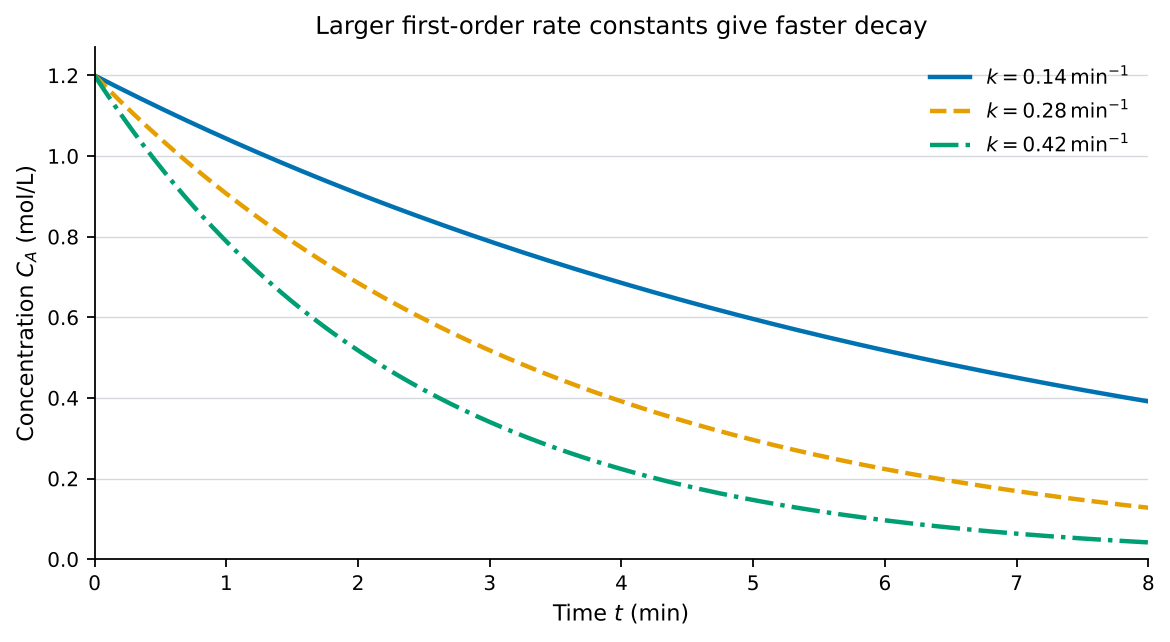

In [4]:
# Make a dense time axis from zero through eight minutes for smooth curves.
dense_time = np.linspace(0.0, 8.0, 321)
# Choose three illustrative positive rates to compare on one set of axes.
illustrative_rates = [0.14, 0.28, 0.42]
# Create one consistently sized figure for the effect of the rate constant.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Assign a distinct color and line pattern to each model curve.
line_styles = ["-", "--", "-."]
# Evaluate and plot each candidate rate at all the same physical times.
for index, rate in enumerate(illustrative_rates):
    # Compute concentrations from the reusable model function.
    curve = first_order(dense_time, C0, rate)
    # Use both color and line style to distinguish the compared rates.
    ax.plot(dense_time, curve, color=list(colors.values())[index], linestyle=line_styles[index], linewidth=2.0, label=fr"$k={rate:.2f}\,\mathrm{{min^{{-1}}}}$")
# Label time in minutes because the rate constant is expressed per minute.
ax.set_xlabel("Time $t$ (min)")
# Label concentration in moles per liter.
ax.set_ylabel("Concentration $C_A$ (mol/L)")
# Give the plot a specific physical interpretation.
ax.set_title("Larger first-order rate constants give faster decay")
# Display the entire modeled time interval.
ax.set_xlim(0.0, 8.0)
# Show zero concentration as a physically meaningful lower reference.
ax.set_ylim(0.0, 1.27)
# Identify the compared rate constants without obscuring the curves.
ax.legend(loc="upper right", frameon=False)
# Add subtle horizontal guides for reading concentrations.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the figure in the notebook.
plt.show()

**Figure 1.** Three first-order predictions from the same initial concentration. Here $k$ is deliberately varied; the curves are model predictions, not measurements.

### Optional numerical connection: advance in small steps

Instead of using the exponential formula, approximate the amount lost over a short time $\Delta t$ by $kC_{\mathrm{old}}\Delta t$:

$$C_{\mathrm{new}}=C_{\mathrm{old}}(1-k\Delta t).$$

This is the explicit Euler method. If $0\le k\Delta t\le1$, a nonnegative concentration stays nonnegative under this simple update. That condition is a positivity check; a small time step is still needed for accuracy. We compare two time steps with the exact exponential formula.

In [5]:
# Define a numerical time-stepping function for first-order disappearance.
def euler_decay(initial, rate, time_step, number_of_steps):
    # Reject a step size that would make a positive concentration negative.
    if not (0.0 < rate * time_step <= 1.0):
        # Explain the admissible time-step condition to the student.
        raise ValueError("Euler decay requires 0 < rate*dt <= 1 for nonnegative concentrations.")
    # Create every physical time, including the starting time at index zero.
    times = np.arange(number_of_steps + 1) * time_step
    # Allocate one concentration entry per stored time.
    values = np.empty(number_of_steps + 1)
    # Set the first stored entry to the prepared initial concentration.
    values[0] = initial
    # Update the concentration one complete time step at a time.
    for index in range(number_of_steps):
        # Subtract the amount predicted to disappear during this step.
        values[index + 1] = values[index] * (1.0 - rate * time_step)
    # Return the paired time and concentration arrays for later comparisons.
    return times, values

In [6]:
# Compute eight one-minute Euler updates to reach eight minutes.
coarse_time, coarse_values = euler_decay(C0, k_true, 1.0, 8)
# Compute 32 quarter-minute updates over the same total time.
fine_time, fine_values = euler_decay(C0, k_true, 0.25, 32)
# Evaluate the independent exponential answer at the shared final time.
exact_final = first_order(8.0, C0, k_true)
# Report both approximations and the exact value at eight minutes.
print(f"At 8 min: Euler dt=1 gives {coarse_values[-1]:.4f}; dt=0.25 gives {fine_values[-1]:.4f}; exact gives {exact_final:.4f} mol/L")
# Confirm that the shorter time step improved this particular final value.
assert abs(fine_values[-1] - exact_final) < abs(coarse_values[-1] - exact_final)

At 8 min: Euler dt=1 gives 0.0867; dt=0.25 gives 0.1177; exact gives 0.1278 mol/L


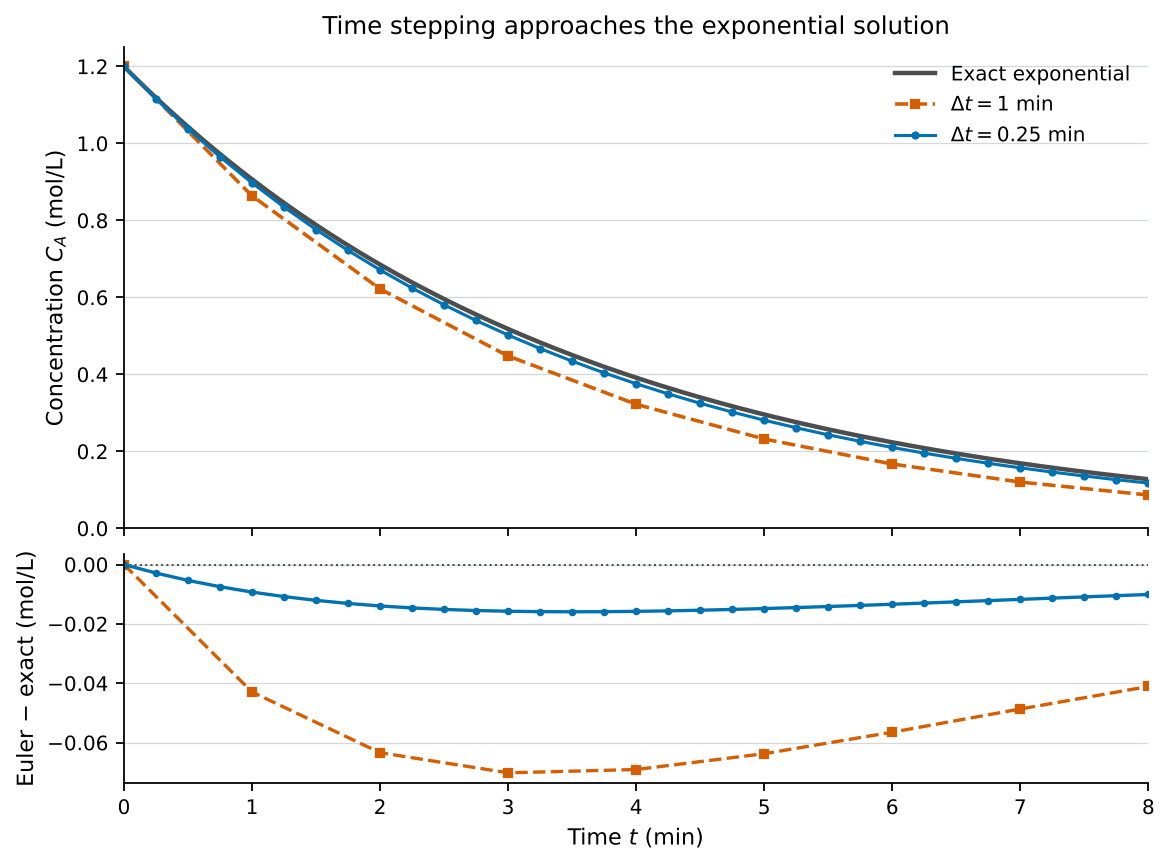

In [7]:
# Arrange a concentration plot above a smaller signed-error plot.
fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.3), sharex=True, gridspec_kw={"height_ratios": [2.1, 1.0]}, layout="constrained")
# Plot the exact exponential on the upper physical-concentration scale.
axes[0].plot(dense_time, first_order(dense_time, C0, k_true), color=colors["gray"], linewidth=2.0, label="Exact exponential")
# Plot the coarse Euler values with markers at their one-minute steps.
axes[0].plot(coarse_time, coarse_values, "s--", color=colors["red"], markersize=4.0, linewidth=1.6, label=r"$\Delta t=1$ min")
# Plot the finer Euler values with smaller quarter-minute markers.
axes[0].plot(fine_time, fine_values, "o-", color=colors["blue"], markersize=2.7, linewidth=1.4, label=r"$\Delta t=0.25$ min")
# Identify concentration and its unit on the upper axis.
axes[0].set_ylabel("Concentration $C_A$ (mol/L)")
# State the purpose of the two-panel comparison.
axes[0].set_title("Time stepping approaches the exponential solution")
# Identify the two numerical step sizes and analytic formula.
axes[0].legend(loc="upper right", frameon=False)
# Keep the upper panel's lower concentration limit physical.
axes[0].set_ylim(0.0, 1.25)
# Mark zero error as a dashed horizontal reference in the lower panel.
axes[1].axhline(0.0, color=colors["gray"], linewidth=0.9, linestyle=":")
# Draw coarse numerical error against the exact formula at the same times.
axes[1].plot(coarse_time, coarse_values - first_order(coarse_time, C0, k_true), "s--", color=colors["red"], markersize=3.5)
# Draw fine numerical error against the exact formula at its own times.
axes[1].plot(fine_time, fine_values - first_order(fine_time, C0, k_true), "o-", color=colors["blue"], markersize=2.4)
# Define the sign convention and unit of the lower panel's difference.
axes[1].set_ylabel("Euler − exact (mol/L)")
# Label the common time coordinate only on the lower panel.
axes[1].set_xlabel("Time $t$ (min)")
# Show the full modeled interval from zero through eight minutes.
axes[1].set_xlim(0.0, 8.0)
# Use light horizontal guides on both panels without obscuring data.
axes[0].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Add corresponding guides for numerical errors in the lower panel.
axes[1].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the two-panel numerical comparison.
plt.show()

**Figure 2.** Explicit Euler approximations and the exact first-order model (upper panel), followed by their signed numerical errors (lower panel). A smaller $\Delta t$ improves this example without changing the reaction model.

In [8]:
# Choose progressively shorter steps that all divide eight minutes exactly.
step_sizes = [1.0, 0.5, 0.25, 0.125]
# Create an empty list for the final-time errors in concentration units.
euler_errors = []
# Check the effect of changing only the time step.
for trial_step in step_sizes:
    # Calculate how many complete steps reach the common eight-minute endpoint.
    count = int(round(8.0 / trial_step))
    # Run Euler's rule with the current temporal resolution.
    trial_times, trial_values = euler_decay(C0, k_true, trial_step, count)
    # Compare the last numerical value with the exact prediction at eight minutes.
    error = abs(trial_values[-1] - exact_final)
    # Keep the error for a simple numerical trend check.
    euler_errors.append(error)
    # Show time step, step count, and final absolute error with units.
    print(f"dt={trial_step:.3f} min; {count:2d} steps; final absolute error={error:.5f} mol/L")
# Confirm that this controlled time-step refinement reduces the final error.
assert all(euler_errors[i] > euler_errors[i + 1] for i in range(3))

dt=1.000 min;  8 steps; final absolute error=0.04109 mol/L
dt=0.500 min; 16 steps; final absolute error=0.02031 mol/L
dt=0.250 min; 32 steps; final absolute error=0.01009 mol/L
dt=0.125 min; 64 steps; final absolute error=0.00503 mol/L


## 3. Make a small measurement dataset

We now pretend that $k$ is unknown. The observed times range from 0 to 8 min, with more measurements early when the concentration changes quickly. The prepared $C_0=1.20\ \mathrm{mol/L}$ is treated as known. To create reproducible **synthetic data**, add independent Gaussian measurement deviations of standard deviation $\sigma=0.025\ \mathrm{mol/L}$ to the first-order concentrations. The random seed makes the same teaching dataset appear on every run. This assumed error model is an example, not a property established for an instrument.

In [9]:
# Store eleven measurement times in minutes, including the initial instant.
measurement_times = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0])
# Set the known standard deviation of the synthetic additive measurement error.
sigma_measurement = 0.025
# Initialize a dedicated random-number generator with a reproducible seed.
data_rng = np.random.default_rng(1701)
# Compute the noiseless concentrations used only to construct this teaching dataset.
hidden_values = first_order(measurement_times, C0, k_true)
# Add one independent random measurement deviation at each sampling time.
observed = hidden_values + data_rng.normal(0.0, sigma_measurement, size=len(measurement_times))
# Print a compact table so students can see actual numeric input to the fit.
for time, concentration in zip(measurement_times, observed):
    # Display a row with time and its measured concentration in explicit units.
    print(f"t={time:4.1f} min    observed C={concentration:.4f} mol/L")
# Check that taking a logarithm later would be permissible for this particular sample.
assert np.all(observed > 0.0)

t= 0.0 min    observed C=1.2110 mol/L
t= 0.5 min    observed C=1.0514 mol/L
t= 1.0 min    observed C=0.9240 mol/L
t= 1.5 min    observed C=0.7680 mol/L
t= 2.0 min    observed C=0.7027 mol/L
t= 3.0 min    observed C=0.4774 mol/L
t= 4.0 min    observed C=0.4292 mol/L
t= 5.0 min    observed C=0.2653 mol/L
t= 6.0 min    observed C=0.2543 mol/L
t= 7.0 min    observed C=0.1428 mol/L
t= 8.0 min    observed C=0.1434 mol/L


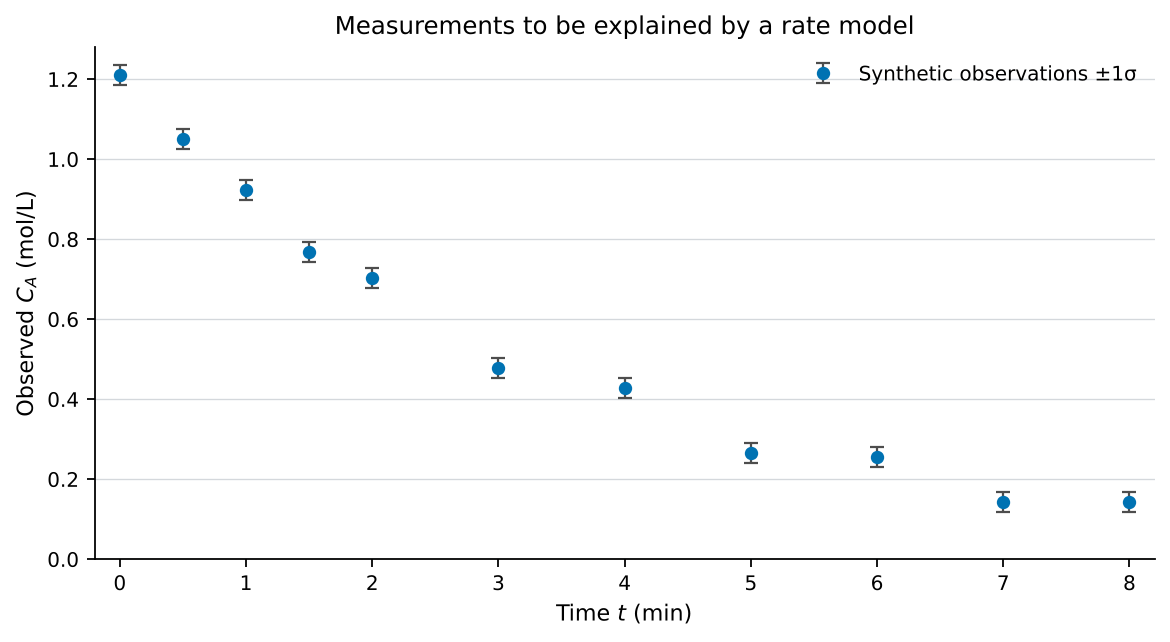

In [10]:
# Create a clean figure for the measured concentrations alone.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Draw each observation with an illustrative one-standard-deviation error bar.
ax.errorbar(measurement_times, observed, yerr=sigma_measurement, fmt="o", color=colors["blue"], ecolor=colors["gray"], capsize=3, markersize=5, elinewidth=1.0, label="Synthetic observations ±1σ")
# Put time and its unit on the horizontal axis.
ax.set_xlabel("Time $t$ (min)")
# Put concentration and its unit on the vertical axis.
ax.set_ylabel("Observed $C_A$ (mol/L)")
# Explain the figure without revealing the hidden generating curve.
ax.set_title("Measurements to be explained by a rate model")
# Include all measurement times and a little outer margin.
ax.set_xlim(-0.2, 8.2)
# Keep the full physical concentration range visible.
ax.set_ylim(0.0, 1.28)
# Explain the error bars as the assumed standard deviation.
ax.legend(loc="upper right", frameon=False)
# Add faint horizontal reference lines for reading data points.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the observations before fitting a model to them.
plt.show()

**Figure 3.** The eleven generated observations and assumed $\pm1\sigma$ error bars. The stated error model is known to us because we constructed the dataset; in a real experiment, measurement uncertainty must be independently justified or estimated.

## 4. Fit the rate constant with least squares

For a trial $k$, calculate a predicted concentration at every measured time. A **residual** is observed minus predicted concentration. The **sum of squared errors**, $\mathrm{SSE}(k)=\sum_i[C_{i,\mathrm{obs}}-C_0e^{-kt_i}]^2$, assigns a score to each trial. A smaller score means a closer fit in the original concentration units. Because all synthetic observations have the same assumed $\sigma$, unweighted SSE is appropriate for this exercise. If uncertainties differ substantially across observations, the fitting rule should account for them.

In [11]:
# Define one numerical score for a proposed first-order rate constant.
def sum_squared_errors(rate, times, measurements, initial):
    # Predict concentrations at exactly the measurement times.
    predictions = first_order(times, initial, rate)
    # Compute observed minus predicted values, with units of mol/L.
    residuals = measurements - predictions
    # Sum their squared values to give a score in (mol/L)².
    return np.sum(residuals**2)
# Check that a score cannot be negative because every term is a square.
assert sum_squared_errors(k_true, measurement_times, observed, C0) >= 0.0

In [12]:
# Search 551 positive trial rates from 0.05 through 0.60 per minute.
coarse_rates = np.linspace(0.05, 0.60, 551)
# Evaluate the objective separately for each candidate rate.
coarse_scores = np.array([sum_squared_errors(rate, measurement_times, observed, C0) for rate in coarse_rates])
# Find the position of the smallest SSE in the candidate array.
coarse_index = np.argmin(coarse_scores)
# Translate the winning array position into a rate with physical units.
coarse_best = coarse_rates[coarse_index]
# Report both the trial rate and the minimized score.
print(f"Coarse best k={coarse_best:.3f} min⁻¹; SSE={coarse_scores[coarse_index]:.6f} (mol/L)²")
# Confirm that the selected rate is within the searched interval.
assert 0.05 <= coarse_best <= 0.60

Coarse best k=0.280 min⁻¹; SSE=0.007080 (mol/L)²


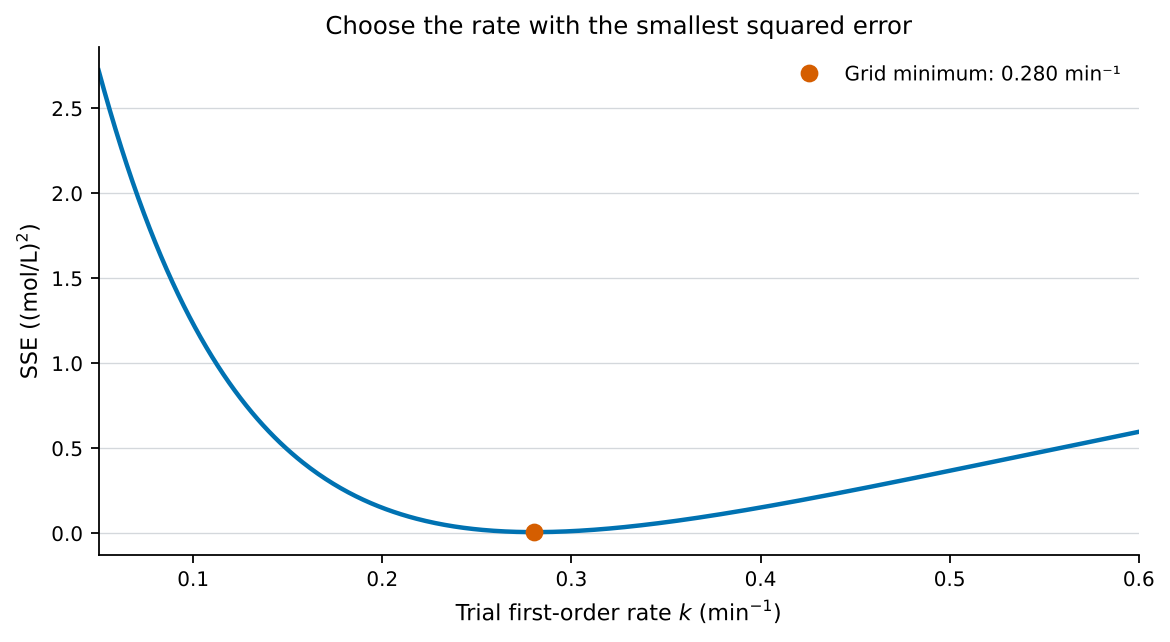

In [13]:
# Create a single-panel figure for the least-squares objective landscape.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Draw how the sum of squared errors changes with candidate rate.
ax.plot(coarse_rates, coarse_scores, color=colors["blue"], linewidth=2.0)
# Mark the minimizing sampled candidate with a contrasting point.
ax.plot(coarse_best, coarse_scores[coarse_index], "o", color=colors["red"], markersize=7, label=f"Grid minimum: {coarse_best:.3f} min⁻¹")
# Identify the horizontal parameter and its reciprocal-minute unit.
ax.set_xlabel("Trial first-order rate $k$ (min$^{-1}$)")
# Identify SSE and its squared concentration unit.
ax.set_ylabel("SSE ((mol/L)$^2$)")
# State what the curve teaches about fitting as a search problem.
ax.set_title("Choose the rate with the smallest squared error")
# Restrict the figure to the range that was actually searched.
ax.set_xlim(coarse_rates[0], coarse_rates[-1])
# Show the minimum's numerical value in a compact unobstructed legend.
ax.legend(loc="upper right", frameon=False)
# Add faint horizontal guides for comparing scores.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the objective curve and chosen parameter.
plt.show()

**Figure 4.** SSE over the specified one-parameter search interval. The dot is the best *sampled* rate. Refining the grid improves the numerical resolution of the search; it cannot remove measurement noise or model inadequacy.

In [14]:
# Make a denser grid covering two hundredths per minute on each side.
refined_rates = np.linspace(coarse_best - 0.02, coarse_best + 0.02, 401)
# Recalculate least-squares scores on this smaller and more detailed interval.
refined_scores = np.array([sum_squared_errors(rate, measurement_times, observed, C0) for rate in refined_rates])
# Locate the lowest score found on the refined interval.
best_index = np.argmin(refined_scores)
# Record the fitted rate for every later prediction and check.
k_fit = refined_rates[best_index]
# Compare the fitted rate to the value used to generate the synthetic data.
print(f"Fitted k={k_fit:.4f} min⁻¹; generating value={k_true:.4f} min⁻¹; difference={k_fit-k_true:+.4f} min⁻¹")
# Check that the new rate is positive and not pinned to a search boundary.
assert k_fit > 0.0 and 0 < best_index < len(refined_rates) - 1

Fitted k=0.2803 min⁻¹; generating value=0.2800 min⁻¹; difference=+0.0003 min⁻¹


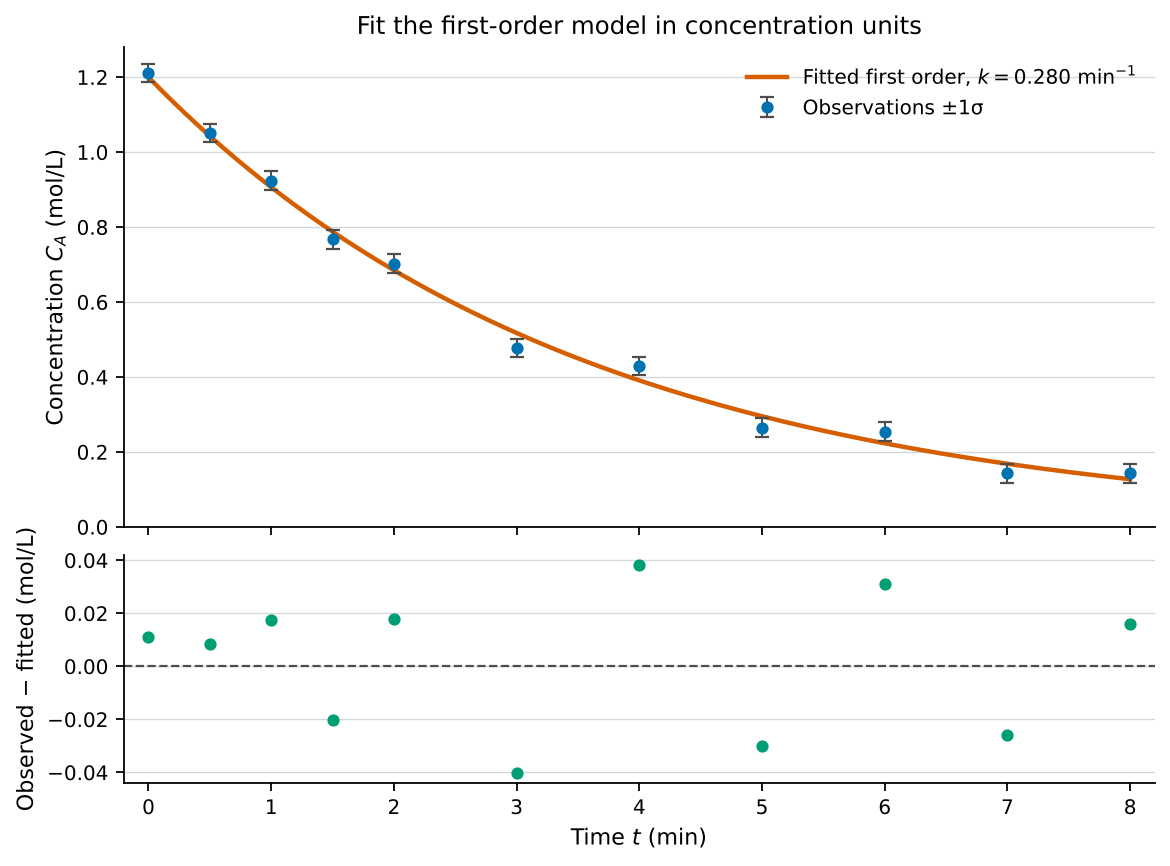

In [15]:
# Compute fitted concentrations at the eleven observed times.
fitted_at_data = first_order(measurement_times, C0, k_fit)
# Define residuals as measurement minus fitted prediction.
residuals = observed - fitted_at_data
# Create two aligned panels for the data fit and its residual diagnostic.
fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.3), sharex=True, gridspec_kw={"height_ratios": [2.1, 1.0]}, layout="constrained")
# Draw the fitted first-order model across a smooth time grid.
axes[0].plot(dense_time, first_order(dense_time, C0, k_fit), color=colors["red"], linewidth=2.0, label=fr"Fitted first order, $k={k_fit:.3f}$ min$^{{-1}}$")
# Draw synthetic observations and their assumed measurement uncertainty.
axes[0].errorbar(measurement_times, observed, yerr=sigma_measurement, fmt="o", color=colors["blue"], ecolor=colors["gray"], capsize=3, markersize=4.5, elinewidth=0.9, label="Observations ±1σ")
# Identify concentration and its unit in the upper panel.
axes[0].set_ylabel("Concentration $C_A$ (mol/L)")
# Give the model-fit comparison a descriptive title.
axes[0].set_title("Fit the first-order model in concentration units")
# Use a compact legend that does not hide the early measurements.
axes[0].legend(loc="upper right", frameon=False)
# Use zero as a physically meaningful concentration reference.
axes[0].set_ylim(0.0, 1.28)
# Mark zero residual as the reference in the lower diagnostic panel.
axes[1].axhline(0.0, color=colors["gray"], linestyle="--", linewidth=1.0)
# Show signed residuals at the actual observation times.
axes[1].plot(measurement_times, residuals, "o", color=colors["green"], markersize=4.5)
# Clarify the residual sign and concentration unit.
axes[1].set_ylabel("Observed − fitted (mol/L)")
# Put physical time and its unit on the shared bottom axis.
axes[1].set_xlabel("Time $t$ (min)")
# Show the full data collection interval.
axes[1].set_xlim(-0.2, 8.2)
# Use faint horizontal guides in both panels.
axes[0].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Add matching guides to the residual scale.
axes[1].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render both the fit and its diagnostic view.
plt.show()

**Figure 5.** Fitted concentration curve and measured points (upper panel), with signed residuals at the measurement times (lower panel). A curve can appear plausible while residuals reveal systematic departures; here the measurements were generated from this model, but any individual noise realization can still look uneven.

In [16]:
# Calculate the root-mean-square discrepancy using all observations.
rmse = np.sqrt(np.mean(residuals**2))
# Estimate noise spread after fitting one parameter from eleven observations.
residual_scale = np.sqrt(np.sum(residuals**2) / (len(observed) - 1))
# Report both descriptive error measures alongside the assumed data noise.
print(f"Residual mean={np.mean(residuals):+.4f} mol/L; RMSE={rmse:.4f} mol/L; fitted residual scale={residual_scale:.4f} mol/L; generating σ={sigma_measurement:.4f} mol/L")
# Check that the fitted curve returns exactly the prepared C0 at t=0.
assert np.isclose(first_order(0.0, C0, k_fit), C0)

Residual mean=+0.0021 mol/L; RMSE=0.0254 mol/L; fitted residual scale=0.0266 mol/L; generating σ=0.0250 mol/L


The residual average need not be exactly zero because we fitted $k$ while keeping $C_0$ fixed, and because this dataset has random error. The estimated residual scale divides SSE by $n-1$ before taking a square root: we used $n=11$ observations to fit one parameter. These summary numbers do not replace looking at residuals against time. A patterned residual plot can signal a missing process or an unsuitable error model.

### Optional check: does one observation dominate?

Repeat the fit eleven times, leaving out a different observation each time. The collection of estimates shows how sensitive this dataset's result is to a single point. These are **not** eleven independent experiments and their range is **not** a formal confidence interval. We reuse the broad original search grid so a leave-one-out answer cannot be trapped by the narrow refinement interval.

In [17]:
# Store fitted rates from repeated one-observation-omitted analyses.
leave_one_out_rates = []
# Remove each of the eleven observations in turn.
for omitted in range(len(observed)):
    # Construct a mask that initially includes every observation.
    keep = np.ones(len(observed), dtype=bool)
    # Remove the single selected observation from this particular fit.
    keep[omitted] = False
    # Recalculate one SSE value per candidate using the retained measurements.
    trial_scores = np.array([sum_squared_errors(rate, measurement_times[keep], observed[keep], C0) for rate in coarse_rates])
    # Store the best broad-grid rate for this omitted-observation case.
    leave_one_out_rates.append(coarse_rates[np.argmin(trial_scores)])
# Show the full range rather than claiming an exact uncertainty interval.
print(f"Leave-one-out fitted k values range from {min(leave_one_out_rates):.3f} to {max(leave_one_out_rates):.3f} min⁻¹")
# Confirm that one rate was calculated for each available observation.
assert len(leave_one_out_rates) == len(observed)

Leave-one-out fitted k values range from 0.276 to 0.285 min⁻¹


## 5. How uncertain is the fitted rate? (optional)

A useful thought experiment is to repeat the measurements many times under the *assumed* noise model. We cannot actually repeat a laboratory experiment here, so we create 400 new synthetic datasets around the **fitted** curve, using the known teaching error standard deviation $\sigma=0.025\ \mathrm{mol/L}$. We refit $k$ for each one. This **parametric simulation interval** is conditional on a precisely known $C_0$, first-order behavior, independent Gaussian errors, the chosen times, and the chosen search range. It does not quantify uncertainty about the model itself.

In [18]:
# Choose a broad, fine rate grid to refit each simulated repeat dataset.
bootstrap_grid = np.linspace(0.12, 0.48, 1441)
# Precompute model values for every candidate rate at all measurement times.
bootstrap_predictions = first_order(measurement_times[None, :], C0, bootstrap_grid[:, None])
# Use a separate generator so this calculation cannot alter the teaching data.
bootstrap_rng = np.random.default_rng(1909)
# Choose the number of simulated independent repetitions of the experiment.
repetitions = 400
# Allocate a place to store the rate fitted in each repeated experiment.
bootstrap_rates = np.empty(repetitions)
# Simulate and refit each full measurement set under the stated error model.
for repetition in range(repetitions):
    # Create eleven new noisy measurements around the previously fitted curve.
    repeat_data = first_order(measurement_times, C0, k_fit) + bootstrap_rng.normal(0.0, sigma_measurement, size=len(measurement_times))
    # Compute an SSE for every candidate rate against this one repeat dataset.
    repeat_scores = np.sum((bootstrap_predictions - repeat_data[None, :])**2, axis=1)
    # Store the candidate with the lowest score for this repeat.
    bootstrap_rates[repetition] = bootstrap_grid[np.argmin(repeat_scores)]
# Find the central 95% limits of the simulated fitted-rate distribution.
rate_limits = np.quantile(bootstrap_rates, [0.025, 0.975])
# Report both limits with their reciprocal-minute unit.
print(f"Conditional simulated 95% interval for k: [{rate_limits[0]:.4f}, {rate_limits[1]:.4f}] min⁻¹")
# Make sure the simulated rates did not pile up against the search boundaries.
assert np.min(bootstrap_rates) > bootstrap_grid[0] and np.max(bootstrap_rates) < bootstrap_grid[-1]

Conditional simulated 95% interval for k: [0.2702, 0.2940] min⁻¹


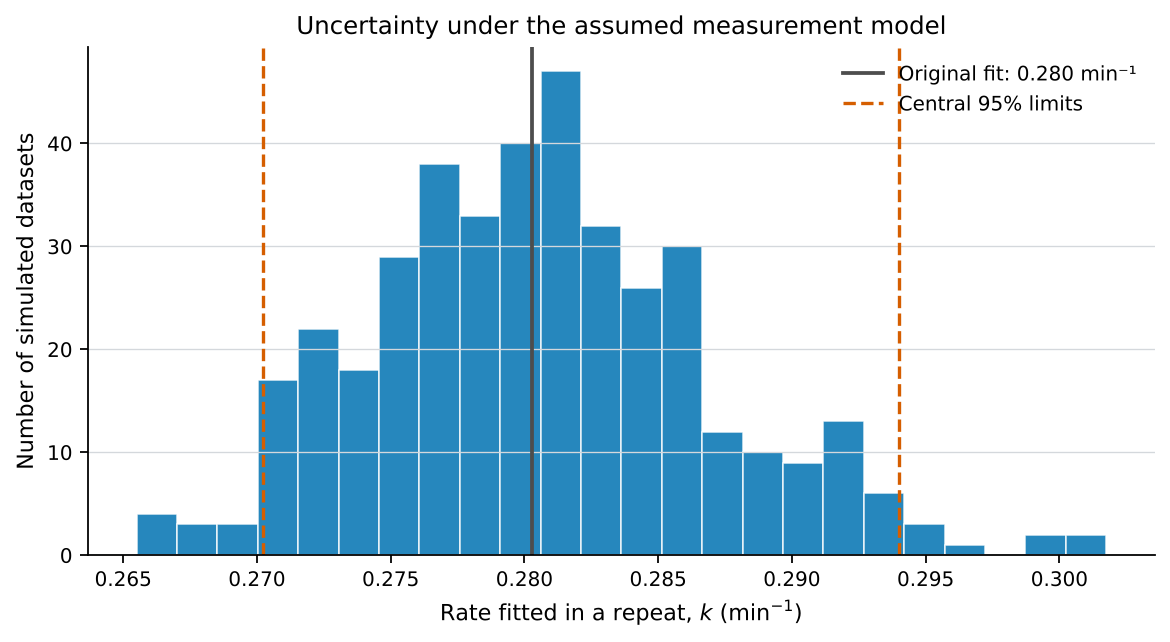

In [19]:
# Make a histogram of the rates fitted to repeated synthetic datasets.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Count how often fitted rates fall in each of 24 equal-width bins.
ax.hist(bootstrap_rates, bins=24, color=colors["blue"], edgecolor="white", linewidth=0.7, alpha=0.85)
# Mark the original fitted rate with a dark solid vertical line.
ax.axvline(k_fit, color=colors["gray"], linewidth=1.7, label=f"Original fit: {k_fit:.3f} min⁻¹")
# Mark the lower simulated quantile with a dashed line.
ax.axvline(rate_limits[0], color=colors["red"], linewidth=1.5, linestyle="--", label="Central 95% limits")
# Mark the upper simulated quantile using the same line style and color.
ax.axvline(rate_limits[1], color=colors["red"], linewidth=1.5, linestyle="--")
# Name the fitted rate and its unit along the horizontal axis.
ax.set_xlabel("Rate fitted in a repeat, $k$ (min$^{-1}$)")
# Clarify that the vertical axis counts simulations rather than measurements.
ax.set_ylabel("Number of simulated datasets")
# State the conditional nature of this simulated distribution.
ax.set_title("Uncertainty under the assumed measurement model")
# Identify the original fit and the two central quantiles.
ax.legend(loc="upper right", frameon=False)
# Use faint horizontal guides for reading histogram frequencies.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the uncertainty diagnostic.
plt.show()

**Figure 6.** Distribution of fitted $k$ values from 400 simulated repeat datasets. Dashed lines enclose the central 95% of those fitted values under the stated model and error assumptions. This is an illustrative, simulation-based interval, not proof that the physical reaction obeys a first-order law.

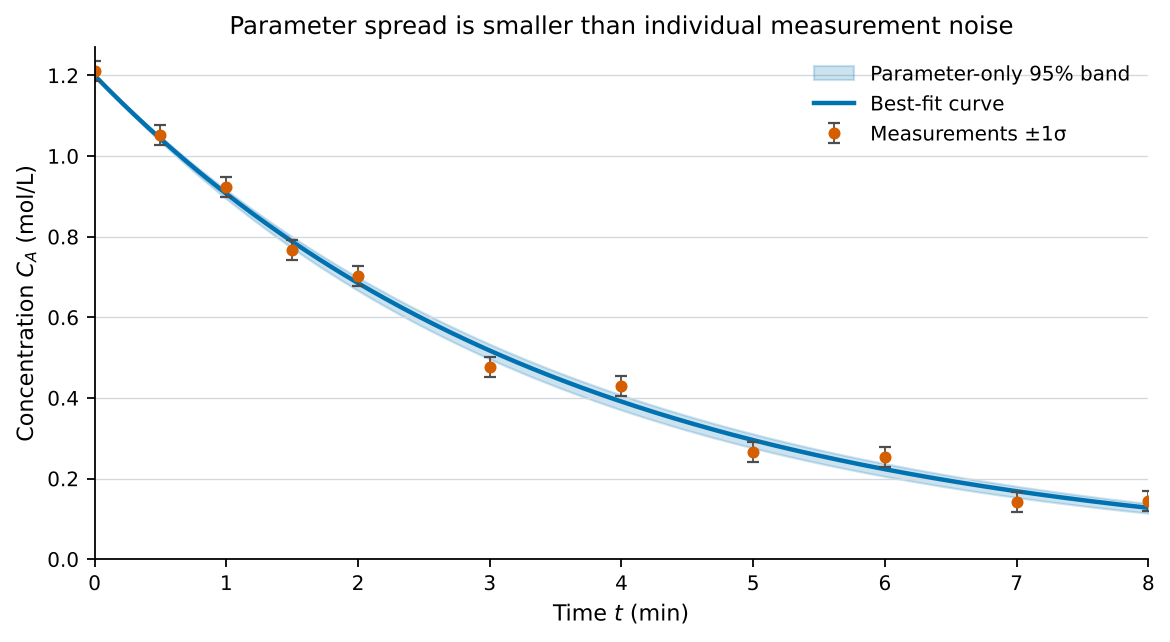

In [20]:
# Compute a full concentration curve for every simulated fitted parameter.
parameter_curves = first_order(dense_time[None, :], C0, bootstrap_rates[:, None])
# Find pointwise central 95% bounds of uncertainty in the mean model curve.
curve_limits = np.quantile(parameter_curves, [0.025, 0.975], axis=0)
# Make a figure that keeps measurement scatter separate from parameter spread.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Shade the central range of model curves produced by rate uncertainty alone.
ax.fill_between(dense_time, curve_limits[0], curve_limits[1], color=colors["blue"], alpha=0.20, label="Parameter-only 95% band")
# Draw the best-fit first-order prediction through the middle of the band.
ax.plot(dense_time, first_order(dense_time, C0, k_fit), color=colors["blue"], linewidth=2.0, label="Best-fit curve")
# Show noisy measurements separately using their assumed one-sigma bars.
ax.errorbar(measurement_times, observed, yerr=sigma_measurement, fmt="o", color=colors["red"], ecolor=colors["gray"], capsize=2.5, markersize=4.4, elinewidth=0.8, label="Measurements ±1σ")
# Identify elapsed time and its unit.
ax.set_xlabel("Time $t$ (min)")
# Identify the modeled concentration and its unit.
ax.set_ylabel("Concentration $C_A$ (mol/L)")
# Make clear what the narrow shaded region represents.
ax.set_title("Parameter spread is smaller than individual measurement noise")
# Show the actual time interval of the sample without extrapolation.
ax.set_xlim(0.0, 8.0)
# Keep the full concentration range of the original data in view.
ax.set_ylim(0.0, 1.27)
# Explain the difference between points, best-fit line, and shaded region.
ax.legend(loc="upper right", frameon=False)
# Add subtle horizontal guides for reading concentrations.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the parameter-uncertainty band and the noisy observations.
plt.show()

**Figure 7.** A pointwise band from uncertainty in $k$ **only**. It is narrower than the scatter of individual observations because it does not include the measurement noise of a future observation. It should not be interpreted as a 95% prediction interval for the next measurement.

## 6. Could another rate law also fit? (optional)

Three common simplified models for disappearance of $A$ are

| Model | Concentration before depletion | Rate-constant units |
|---|---|---|
| Zero order | $C_A(t)=C_0-vt$ | $[v]=\mathrm{mol/(L\,min)}$ |
| First order | $C_A(t)=C_0e^{-kt}$ | $[k]=\mathrm{min^{-1}}$ |
| Second order | $C_A(t)=C_0/(1+k_2C_0t)$ | $[k_2]=\mathrm{L/(mol\,min)}$ |

For zero order, we stop the straight-line decrease at zero because a concentration cannot continue below zero. This piecewise rule is a mathematical convenience for the comparison. We hold the prepared $C_0$ fixed and fit **one rate parameter per model** using the same observations and unweighted SSE. Lower SSE on one constructed dataset is useful evidence, but it cannot establish a chemical mechanism by itself.

In [21]:
# Define a zero-order concentration curve with a zero lower bound after depletion.
def zero_order(times, initial, rate_zero):
    # Subtract the same concentration per minute until none remains.
    return np.maximum(initial - rate_zero * times, 0.0)
# Check that this model starts at the prepared initial value.
assert np.isclose(zero_order(0.0, C0, 0.10), C0)

In [22]:
# Search possible zero-order loss rates in mol/(L min).
zero_rate_grid = np.linspace(0.01, 0.25, 481)
# Calculate the residual-squared score for every zero-order candidate.
zero_scores = np.array([np.sum((observed - zero_order(measurement_times, C0, rate))**2) for rate in zero_rate_grid])
# Read the candidate rate with the smallest zero-order SSE.
zero_fit = zero_rate_grid[np.argmin(zero_scores)]
# Keep its SSE for a like-for-like comparison with other one-parameter fits.
zero_sse = np.min(zero_scores)
# Print the fitted parameter with its own units and score.
print(f"Zero order: v={zero_fit:.4f} mol/(L min), SSE={zero_sse:.6f} (mol/L)²")

Zero order: v=0.1880 mol/(L min), SSE=0.147755 (mol/L)²


In [23]:
# Define the integrated second-order prediction for one reactant A.
def second_order(times, initial, rate_second):
    # Divide C0 by one plus a dimensionless rate-times-concentration-times-time term.
    return initial / (1.0 + rate_second * initial * times)
# Verify that the second-order model also begins at C0.
assert np.isclose(second_order(0.0, C0, 0.20), C0)

In [24]:
# Search positive second-order rates with units L/(mol min).
second_rate_grid = np.linspace(0.01, 1.20, 1191)
# Evaluate second-order predictions and squared errors for each candidate.
second_scores = np.array([np.sum((observed - second_order(measurement_times, C0, rate))**2) for rate in second_rate_grid])
# Select the best rate from the evaluated second-order candidates.
second_fit = second_rate_grid[np.argmin(second_scores)]
# Record the smallest second-order SSE for model comparison.
second_sse = np.min(second_scores)
# Use the refined first-order SSE from the same data and fixed C0.
first_sse = np.min(refined_scores)
# Print each SSE together without claiming that one fit proves a mechanism.
print(f"SSE (mol/L)²: zero={zero_sse:.6f}; first={first_sse:.6f}; second={second_sse:.6f}")
# Confirm that all three candidate scores are physically nonnegative.
assert min(zero_sse, first_sse, second_sse) >= 0.0

SSE (mol/L)²: zero=0.147755; first=0.007079; second=0.072624


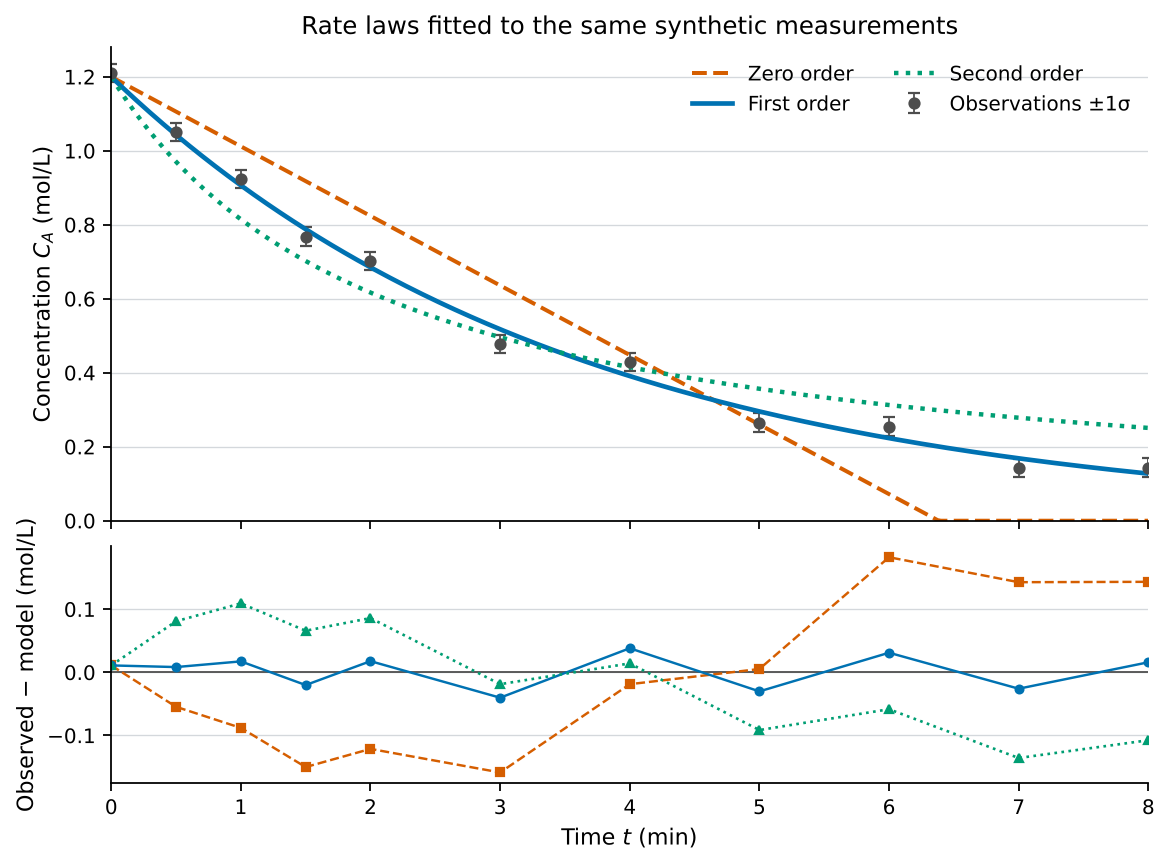

In [25]:
# Evaluate each best-fit model on the same dense time grid for comparison.
zero_curve = zero_order(dense_time, C0, zero_fit)
# Compute the original first-order fit on the common time grid.
first_curve = first_order(dense_time, C0, k_fit)
# Evaluate the second-order fit at the same plotting times.
second_curve = second_order(dense_time, C0, second_fit)
# Create two aligned panels for model curves and their signed residuals.
fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.3), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.0]}, layout="constrained")
# Draw the measured data with one-sigma error bars in the upper panel.
axes[0].errorbar(measurement_times, observed, yerr=sigma_measurement, fmt="o", color=colors["gray"], ecolor=colors["gray"], capsize=2.5, markersize=4.5, elinewidth=0.8, label="Observations ±1σ")
# Plot the fitted zero-order model as a contrasting dashed line.
axes[0].plot(dense_time, zero_curve, color=colors["red"], linestyle="--", linewidth=1.8, label="Zero order")
# Plot the fitted first-order model as a solid blue line.
axes[0].plot(dense_time, first_curve, color=colors["blue"], linewidth=2.1, label="First order")
# Plot the fitted second-order model as a green dotted line.
axes[0].plot(dense_time, second_curve, color=colors["green"], linestyle=":", linewidth=2.0, label="Second order")
# Identify concentration and its unit in the upper panel.
axes[0].set_ylabel("Concentration $C_A$ (mol/L)")
# Describe the controlled one-parameter comparison.
axes[0].set_title("Rate laws fitted to the same synthetic measurements")
# Identify the data and three model predictions in a compact legend.
axes[0].legend(loc="upper right", frameon=False, ncol=2)
# Show the physical nonnegative concentration range.
axes[0].set_ylim(0.0, 1.28)
# Mark zero residual as a common reference for the lower comparisons.
axes[1].axhline(0.0, color=colors["gray"], linestyle="-", linewidth=0.8)
# Plot zero-order residuals at the measurement times.
axes[1].plot(measurement_times, observed - zero_order(measurement_times, C0, zero_fit), "s--", color=colors["red"], markersize=3.5, linewidth=1.1)
# Plot first-order residuals using blue circular markers.
axes[1].plot(measurement_times, residuals, "o-", color=colors["blue"], markersize=3.5, linewidth=1.1)
# Plot second-order residuals using green triangular markers.
axes[1].plot(measurement_times, observed - second_order(measurement_times, C0, second_fit), "^:", color=colors["green"], markersize=3.5, linewidth=1.2)
# Specify residual sign and unit for the lower panel.
axes[1].set_ylabel("Observed − model (mol/L)")
# Specify time in minutes on the shared horizontal axis.
axes[1].set_xlabel("Time $t$ (min)")
# Keep all compared models within the sampled time range.
axes[1].set_xlim(0.0, 8.0)
# Use subtle horizontal guides for reading upper-panel concentrations.
axes[0].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Use matching guides for reading the lower residual panel.
axes[1].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the model and residual comparison.
plt.show()

**Figure 8.** Zero-, first-, and second-order fits using the same prepared $C_0$ and one fitted rate parameter each. Residual patterns and SSE matter in addition to visual overlap. These observations were generated by a first-order model; results on real data could be less decisive, and a good concentration fit does not establish the detailed mechanism.

### Why not always fit a straight line to logarithms?

The first-order formula can be rewritten $\ln C_A=\ln C_0-kt$. A straight-line fit to $(t,\ln C_{\mathrm{obs}})$ may look convenient, provided every observation is positive. However, taking logarithms changes how additive concentration errors are weighted: late small concentrations can be affected disproportionately. The main fit above minimizes errors in the measured **concentration** directly. We compare the two numerical answers as a diagnostic, not as two interchangeable estimators under our assumed additive-noise model.

In [26]:
# Fit a straight line to log concentrations only because all observations are positive.
log_slope, log_intercept = np.polyfit(measurement_times, np.log(observed), 1)
# Translate the negative fitted line slope into a first-order rate constant.
k_log = -log_slope
# Translate the fitted intercept into an implied initial concentration.
C0_log = np.exp(log_intercept)
# Evaluate this log-fit curve's SSE back in the originally measured units.
log_fit_sse = np.sum((observed - first_order(measurement_times, C0_log, k_log))**2)
# Report the changed rate, changed initial concentration, and original-unit SSE.
print(f"Log-linear fit: k={k_log:.4f} min⁻¹, C₀={C0_log:.4f} mol/L; original-unit SSE={log_fit_sse:.6f} (mol/L)²")
# Confirm that the calculated log-fit rate and initial concentration are positive.
assert k_log > 0.0 and C0_log > 0.0

Log-linear fit: k=0.2788 min⁻¹, C₀=1.1964 mol/L; original-unit SSE=0.007250 (mol/L)²


## 7. What if the prepared initial concentration were uncertain? (optional)

So far, $C_0$ has been treated as exactly known, which makes the main fit a one-parameter problem. If it is not known precisely, we can try combinations of $C_0$ and $k$ on a **two-dimensional grid**. Each grid point predicts all eleven concentrations and gets one SSE. The best pair among the tested combinations is the smallest score. This example illustrates a common difficulty: changing one parameter may partly compensate for changing the other. We do not treat the region of similar SSE values as a calibrated confidence region.

In [27]:
# Choose plausible initial concentrations around the prepared nominal value.
initial_grid = np.linspace(0.95, 1.45, 101)
# Choose plausible first-order rates around the earlier one-parameter estimate.
joint_rate_grid = np.linspace(0.17, 0.39, 221)
# Evaluate all initial-concentration and rate combinations at the eleven times.
joint_predictions = initial_grid[:, None, None] * np.exp(-joint_rate_grid[None, :, None] * measurement_times[None, None, :])
# Sum squared concentration residuals over the measurement-time dimension.
joint_scores = np.sum((joint_predictions - observed[None, None, :])**2, axis=2)
# Convert the smallest entry's flat array position into its two grid indices.
initial_index, rate_index = np.unravel_index(np.argmin(joint_scores), joint_scores.shape)
# Read the best tested initial concentration from its grid index.
C0_joint = initial_grid[initial_index]
# Read the best tested rate constant from its separate grid index.
k_joint = joint_rate_grid[rate_index]
# Print the joint fit without claiming it is directly comparable to a one-parameter uncertainty interval.
print(f"Joint grid fit: C₀={C0_joint:.3f} mol/L, k={k_joint:.3f} min⁻¹, SSE={joint_scores[initial_index,rate_index]:.6f} (mol/L)²")
# Ensure the chosen pair lies inside rather than at the limits of the searched grid.
assert 0 < initial_index < len(initial_grid) - 1 and 0 < rate_index < len(joint_rate_grid) - 1

Joint grid fit: C₀=1.210 mol/L, k=0.283 min⁻¹, SSE=0.006894 (mol/L)²


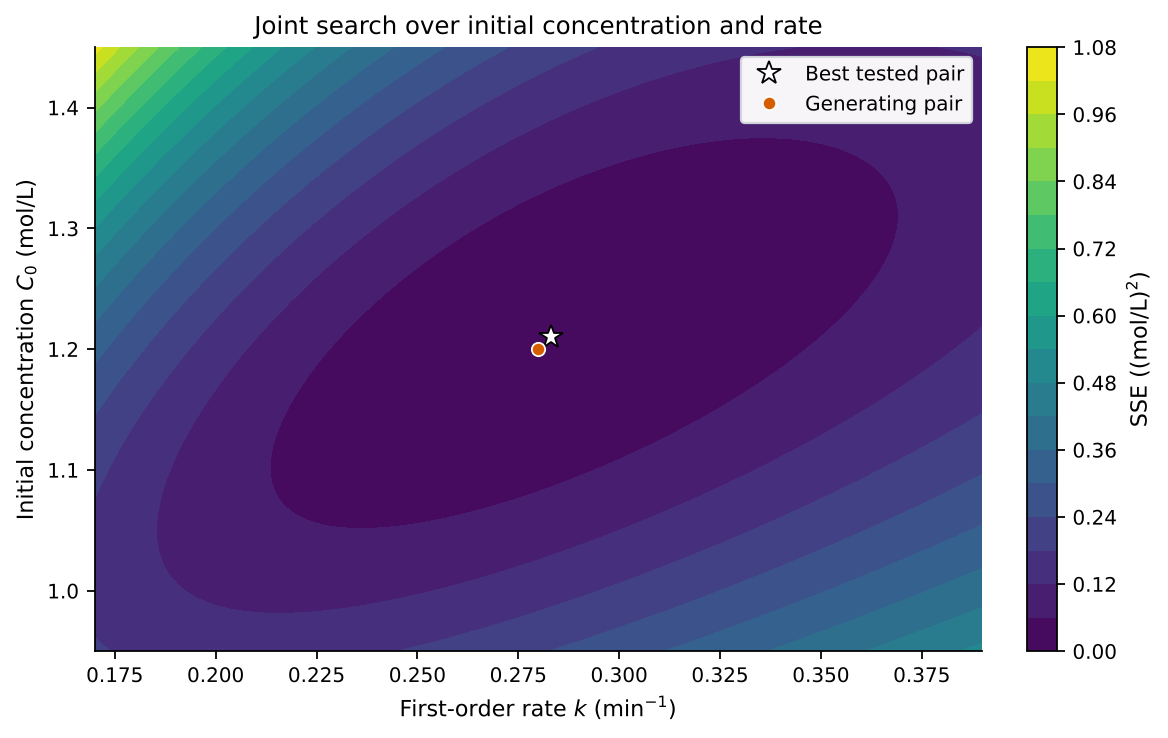

In [28]:
# Create one figure for the two-parameter error landscape.
fig, ax = plt.subplots(figsize=(7.2, 4.5), layout="constrained")
# Color each tested parameter pair by its SSE using a perceptually ordered map.
filled = ax.contourf(joint_rate_grid, initial_grid, joint_scores, levels=18, cmap="viridis")
# Mark the best pair found on the two-dimensional numerical grid.
ax.plot(k_joint, C0_joint, "*", color="white", markeredgecolor="black", markeredgewidth=0.8, markersize=11, label="Best tested pair")
# Show the known generating pair for this synthetic exercise as a separate symbol.
ax.plot(k_true, C0, "o", color=colors["red"], markeredgecolor="white", markeredgewidth=0.8, markersize=6, label="Generating pair")
# Identify the rate constant and its reciprocal-minute unit.
ax.set_xlabel("First-order rate $k$ (min$^{-1}$)")
# Identify initial concentration and its molar concentration unit.
ax.set_ylabel("Initial concentration $C_0$ (mol/L)")
# State that the colored surface represents a search, not a probability map.
ax.set_title("Joint search over initial concentration and rate")
# Distinguish the two markers with an opaque background over the dark contour.
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#D4D8DC", framealpha=0.96)
# Create a color bar to explain the numerical color scale.
bar = fig.colorbar(filled, ax=ax)
# Name the plotted score and its squared concentration unit.
bar.set_label("SSE ((mol/L)$^2$)")
# Render the two-parameter landscape.
plt.show()

**Figure 9.** SSE over tested $(k,C_0)$ pairs; the star shows the lowest grid score, and the circle shows the parameters that generated the synthetic data. The color map reports fit error, **not** a probability or confidence level. The tilted low-score region shows how the two parameters can compensate for each other.

## 8. Translate the fitted parameter into an engineering statement

A number is most useful when its units and consequences are explicit. The fitted first-order half-life is $\ln 2/k_{\mathrm{fit}}$. If we express time in seconds, the numerical value of $k$ changes from $\mathrm{min^{-1}}$ to $\mathrm{s^{-1}}$ by dividing by 60; the physical process stays the same. The **fraction converted** at a time $t$ is $1-C_A(t)/C_0$ for this disappearance model.

In [29]:
# Use the fitted rate to estimate the time for half the original A to remain.
half_life_fit = np.log(2.0) / k_fit
# Express the same fitted rate per second instead of per minute.
k_per_second = k_fit / 60.0
# Calculate the fraction of initial A that has disappeared by eight minutes.
conversion_eight = 1.0 - first_order(8.0, C0, k_fit) / C0
# Print each result with its unit or its dimensionless interpretation.
print(f"Fitted half-life={half_life_fit:.3f} min; k={k_per_second:.6f} s⁻¹; predicted conversion at 8 min={100*conversion_eight:.1f}%")
# Check the half-life prediction against the fitted concentration curve.
assert np.isclose(first_order(half_life_fit, C0, k_fit), C0 / 2.0)

Fitted half-life=2.473 min; k=0.004672 s⁻¹; predicted conversion at 8 min=89.4%


## 9. Guided exercise: when is 75% converted?

At 75% conversion, only $0.25C_0$ remains. Before running the worked solution, try to locate the first time in the interval 0–20 min when the fitted curve crosses this target. **Bisection** repeatedly keeps the half-interval that still contains the crossing. This shows how a simple search algorithm can solve an engineering design question. Then independently check against $t_{75}=\ln(4)/k_{\mathrm{fit}}$ for a first-order model. This time is a model prediction under the fitted parameters, not a guaranteed outcome of an actual experiment.

In [30]:
# Define the remaining concentration corresponding to 75% conversion.
quarter_remaining = 0.25 * C0
# Start with a lower time at which more than a quarter remains.
lower_time = 0.0
# Choose an upper time at which the fitted curve is below one quarter.
upper_time = 20.0
# Verify the target really lies between the two starting predictions.
assert first_order(lower_time, C0, k_fit) > quarter_remaining > first_order(upper_time, C0, k_fit)
# Halve the bracket 30 times to make its final width far below one second.
for iteration in range(30):
    # Calculate the midpoint time of the current bracket.
    middle_time = 0.5 * (lower_time + upper_time)
    # Check whether the concentration is still above the quarter target.
    if first_order(middle_time, C0, k_fit) > quarter_remaining:
        # Keep the later half because disappearance has not yet reached 75%.
        lower_time = middle_time
    # Handle the case where a quarter or less of A remains.
    else:
        # Keep the earlier half because the target crossing is no later than mid.
        upper_time = middle_time
# Use the center of the final narrow bracket as the numerical crossing time.
bisected_time = 0.5 * (lower_time + upper_time)
# Independently calculate the exact model crossing using the logarithm formula.
formula_time = np.log(4.0) / k_fit
# Report both predictions so students can check the loop against a formula.
print(f"75% conversion: bisection t={bisected_time:.4f} min; formula t={formula_time:.4f} min")
# Confirm that the two independent routes agree within the bracket width.
assert abs(bisected_time - formula_time) < 1e-6

75% conversion: bisection t=4.9458 min; formula t=4.9458 min


## What to take away

1. **Physical model:** a first-order rate is proportional to the concentration remaining; its rate constant has units of inverse time. A fitted reaction order does not establish molecular mechanism.
2. **Programming:** one model function generates predictions; a grid search evaluates many rates; an array index identifies the smallest SSE; a loop refines a numerical solution; plots show both fitted curves and residuals.
3. **Measurement judgment:** synthetic data with a fixed random seed are reproducible, not real evidence. Fit in the measurement units when the assumed errors are additive there. Explain parameter uncertainty only with its assumptions.
4. **Model judgment:** a low SSE and a visually good curve are useful checks, while residual patterns and alternate rate laws ask a deeper question. Uncertainty in $C_0$ changes the parameter-fitting problem.

**Further exercises:** (a) increase the synthetic noise standard deviation and observe the fitted $k$ distribution; (b) shorten the experiment to 0–2 min and see how fitting changes; (c) replace the generating model with second order and test which candidate wins; (d) change time units to seconds in both the model and data without changing the physical predictions. Keep the data-generation rate hidden until you have fitted your candidate models.

**Assumptions and limits:** constant volume and temperature, uniform mixing, no parallel pathway, known $C_0$ in the main fit, additive independent errors of constant standard deviation, and a chosen parameter search range. Any real system requires evidence for those assumptions, documented measurement units, and an assessment of repeatability and model adequacy. The simulated interval and shaded band do not include uncertainty about the reaction mechanism or future observation noise.

**Optional primary-source reading:** [MIT OpenCourseWare, *Kinetics: Reaction Rates, Orders, and Half Lives*](https://ocw.mit.edu/courses/5-60-thermodynamics-kinetics-spring-2008/resources/lec_29/) introduces rate laws and half-life; [MIT OpenCourseWare, *Reaction Rates*](https://ocw.mit.edu/courses/3-091sc-introduction-to-solid-state-chemistry-fall-2010/pages/reactions-and-kinetics/23-reaction-rates/) discusses comparing reaction orders; [NIST/SEMATECH e-Handbook, *How can I tell if a model fits my data?*](https://www.itl.nist.gov/div898/handbook/pmd/section4/pmd44.htm) explains residual-based checks. The readings extend beyond what is needed to run this introductory programming notebook.